# African Telecom Stocks: Time Series Analysis

This project studies three listed telecom companies:

- **Airtel Africa** (`AAF.L`)
- **MTN Group** (`MTN.JO`)
- **Vodacom** (`VOD.JO`)

It uses daily market data from Yahoo Finance, then adds a small, separate snapshot of **Airtel Malawi and TNM** from the Malawi Stock Exchange (MSE).

**Important:** Airtel Africa, MTN Group and Vodacom are regional peers, not the same as Airtel Malawi and TNM. Their prices are in different currencies, so we compare percentage returns and rebased prices rather than raw prices.

## What I changed

- Combined the useful parts of both notebooks into one ordered notebook.
- Added checks for empty downloads and missing values.
- Made the date range unambiguous. Yahoo Finance treats `end` as exclusive, so use `2026-01-01` to include data through 31 December 2025.
- Rebased each share from its own first available price instead of filling early gaps with later prices.
- Made the charts and summary tables easier to interpret.
- Kept the prediction section, but made its limitations and timing clearer.

Run the notebook **from top to bottom**. Online data downloads require an internet connection.

## 1. Import the libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Make charts easier to read
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Ticker symbols and the names we want to display
tickers = {
    "AAF.L": "Airtel Africa",
    "MTN.JO": "MTN Group",
    "VOD.JO": "Vodacom"
}

start_date = "2020-01-01"
end_date = "2026-01-01"  # end date is exclusive; this includes 2025-12-31

## 2. Download the share-price data

We request adjusted prices and keep the columns needed for analysis. If a ticker fails to download, the code reports it instead of stopping the whole notebook.

In [2]:
stock_data = {}

for ticker, company in tickers.items():
    print("Downloading:", company)

    data = yf.Ticker(ticker).history(
        start=start_date,
        end=end_date,
        auto_adjust=True
    )

    # Check that the download contains data
    if data.empty:
        print("  No data returned for", ticker, "- check the ticker or internet connection.")
        continue

    # Remove timezone information to make dates easier to work with
    if data.index.tz is not None:
        data.index = data.index.tz_localize(None)

    data.index.name = "Date"

    # Keep only the columns we need and remove rows without a closing price
    data = data[["Open", "High", "Low", "Close", "Volume"]].dropna(subset=["Close"])

    # Sort dates from oldest to newest
    data = data.sort_index()

    stock_data[company] = data

    print("  Rows:", len(data))
    print("  From:", data.index.min().date(), "to", data.index.max().date())

if not stock_data:
    raise ValueError("No stock data was downloaded. Check your internet connection and ticker symbols.")

# Show the first five rows of one downloaded dataset
first_company = list(stock_data.keys())[0]
stock_data[first_company].head()

Downloading: Airtel Africa
  Rows: 1515
  From: 2020-01-02 to 2025-12-31
Downloading: MTN Group
  Rows: 1500
  From: 2020-01-02 to 2025-12-31
Downloading: Vodacom
  Rows: 1500
  From: 2020-01-02 to 2025-12-31


,Open,High,Low,Close,Volume
Date,,,,,
2020-01-02,76.254980,80.444271,76.254980,78.598991,1086111
2020-01-03,78.997970,79.297208,77.152691,78.299759,995180
2020-01-06,79.696199,79.720140,76.105383,78.249893,894623
2020-01-07,76.803574,79.496683,76.703831,79.097710,1073498
2020-01-08,78.349636,78.499248,77.003074,77.551674,814587


## 3. Check the data

A time series should have dates in order. We also check missing values and duplicate dates. A gap between dates is normal when the market is closed for weekends or holidays.

In [3]:
for company, data in stock_data.items():
    print("\n", company)
    print("Dates in order:", data.index.is_monotonic_increasing)
    print("Duplicate dates:", data.index.duplicated().sum())
    print("Missing values in each column:")
    print(data.isna().sum())


 Airtel Africa
Dates in order: True
Duplicate dates: 0
Missing values in each column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

 MTN Group
Dates in order: True
Duplicate dates: 0
Missing values in each column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

 Vodacom
Dates in order: True
Duplicate dates: 0
Missing values in each column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


## 4. Compare closing prices

Raw prices are not directly comparable because the shares trade in different currencies and units. We show raw closing prices separately, then rebase each share to 100 at its first available observation.

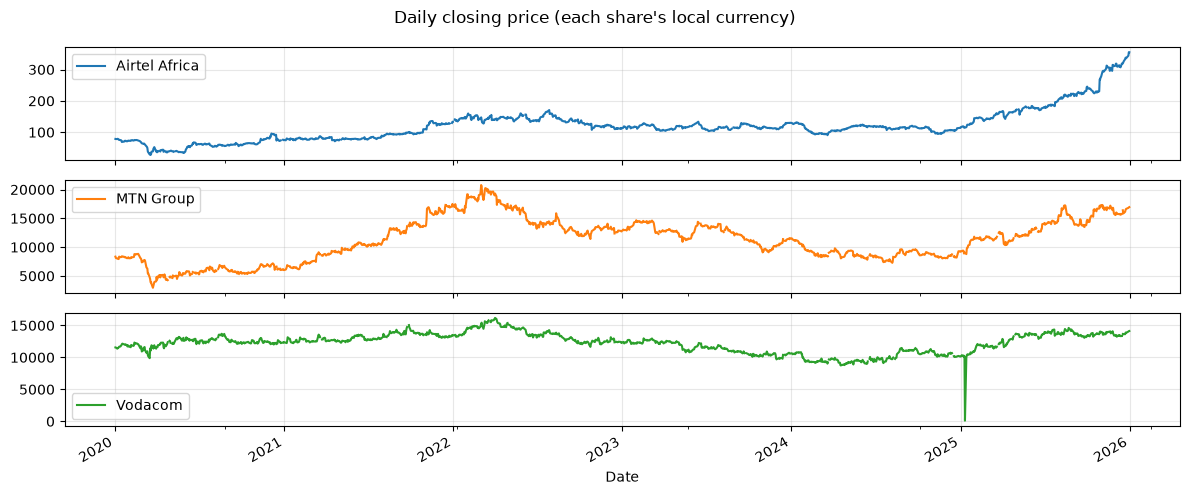

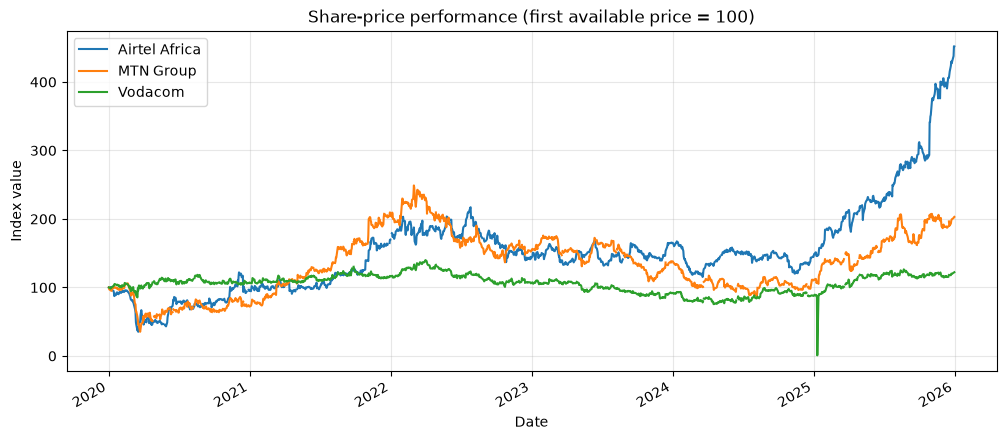

In [4]:
closing_prices = pd.DataFrame({
    company: data["Close"]
    for company, data in stock_data.items()
})

# Raw prices: useful for seeing each share's own price history
closing_prices.plot(subplots=True, title="Daily closing price (each share's local currency)")
plt.tight_layout()
plt.show()

# Rebase each share independently: first available price becomes 100
rebased_prices = closing_prices.copy()

for company in rebased_prices.columns:
    first_price = rebased_prices[company].dropna().iloc[0]
    rebased_prices[company] = rebased_prices[company] / first_price * 100

rebased_prices.plot(title="Share-price performance (first available price = 100)")
plt.ylabel("Index value")
plt.show()

## 5. Resample to weekly and monthly prices

`resample()` groups daily observations into a larger time period. We use the last available closing price in each week or month.

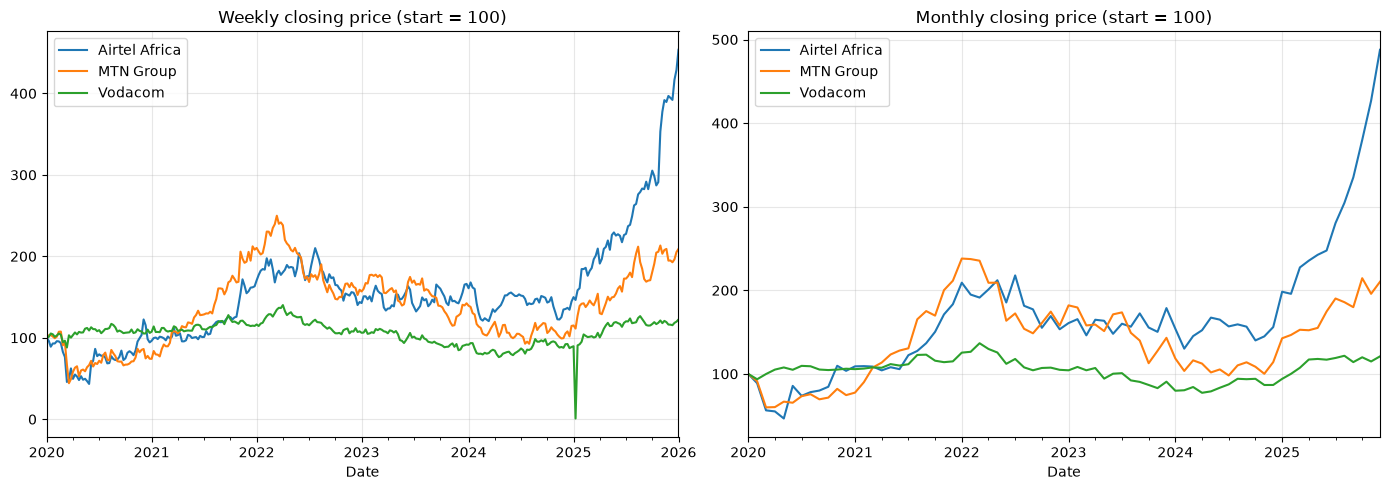

Average monthly return (%):
Airtel Africa    3.19
MTN Group        1.69
Vodacom          0.41
dtype: float64

Monthly return volatility (standard deviation, %):
Airtel Africa    14.71
MTN Group        11.25
Vodacom           5.25
dtype: float64


In [5]:
weekly_prices = closing_prices.resample("W").last()
monthly_prices = closing_prices.resample("ME").last()

# Rebase each series so the charts compare percentage performance
weekly_index = weekly_prices.copy()
monthly_index = monthly_prices.copy()

for company in weekly_index.columns:
    first_value = weekly_index[company].dropna().iloc[0]
    weekly_index[company] = weekly_index[company] / first_value * 100

for company in monthly_index.columns:
    first_value = monthly_index[company].dropna().iloc[0]
    monthly_index[company] = monthly_index[company] / first_value * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
weekly_index.plot(ax=axes[0], title="Weekly closing price (start = 100)")
monthly_index.plot(ax=axes[1], title="Monthly closing price (start = 100)")
plt.tight_layout()
plt.show()

# Monthly percentage returns
monthly_returns = monthly_prices.pct_change() * 100

print("Average monthly return (%):")
print(monthly_returns.mean().round(2))

print("\nMonthly return volatility (standard deviation, %):")
print(monthly_returns.std().round(2))

## 6. 20-day and 200-day moving averages

The 20-day moving average gives a shorter-term view; the 200-day average gives a longer-term view. These are descriptive indicators, not automatic buy or sell signals.

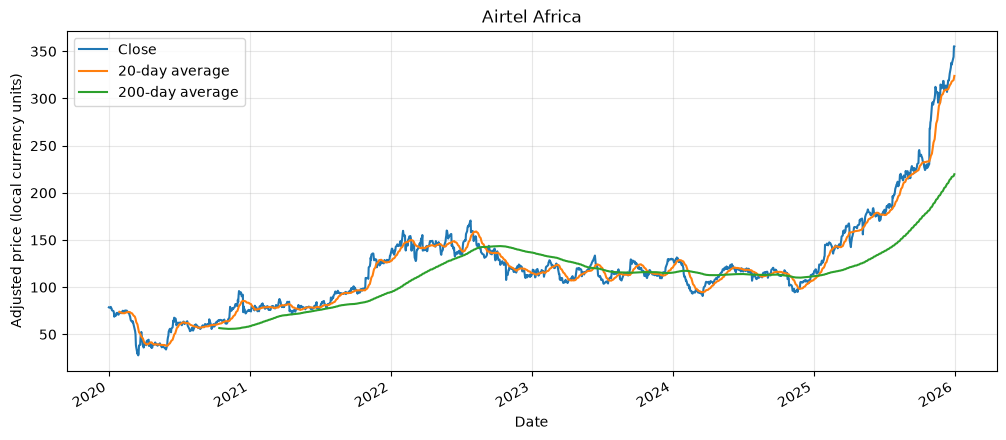

Airtel Africa: latest close is +61.63% from its 200-day average.


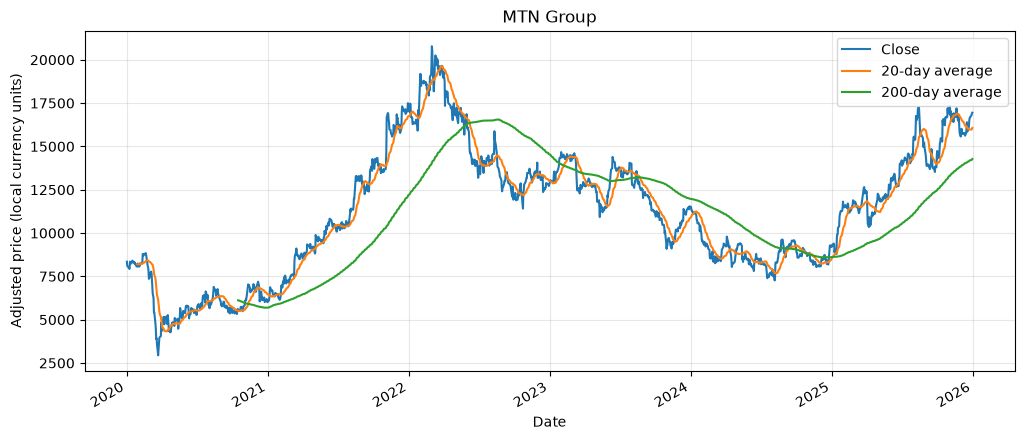

MTN Group: latest close is +18.72% from its 200-day average.


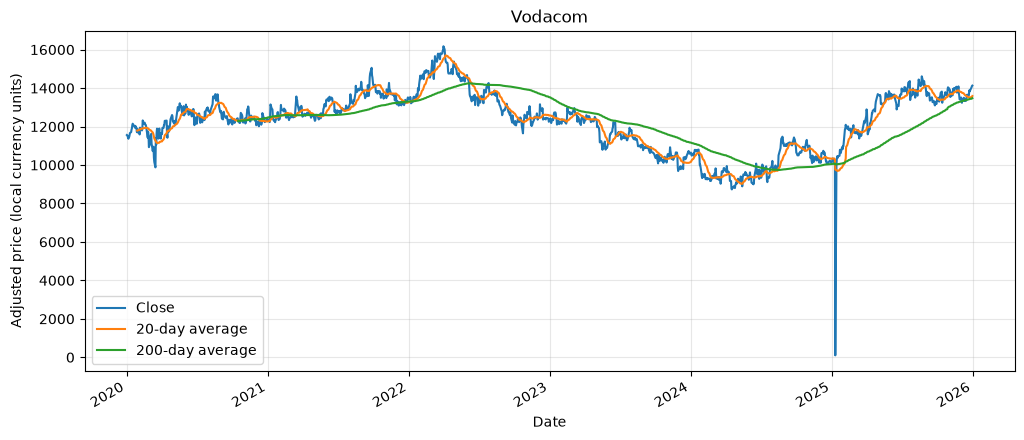

Vodacom: latest close is +4.87% from its 200-day average.


In [6]:
for company, data in stock_data.items():
    chart_data = pd.DataFrame(index=data.index)
    chart_data["Close"] = data["Close"]
    chart_data["20-day average"] = data["Close"].rolling(window=20).mean()
    chart_data["200-day average"] = data["Close"].rolling(window=200).mean()

    chart_data.plot(title=company)
    plt.ylabel("Adjusted price (local currency units)")
    plt.show()

    latest_close = data["Close"].iloc[-1]
    latest_average = data["Close"].rolling(window=200).mean().iloc[-1]

    if pd.notna(latest_average):
        difference = (latest_close / latest_average - 1) * 100
        print(f"{company}: latest close is {difference:+.2f}% from its 200-day average.")

## 7. Trading volume

Share volume is not perfectly comparable across exchanges because each market has different share units and trading practices. Treat this as a rough comparison, not a complete measure of liquidity.

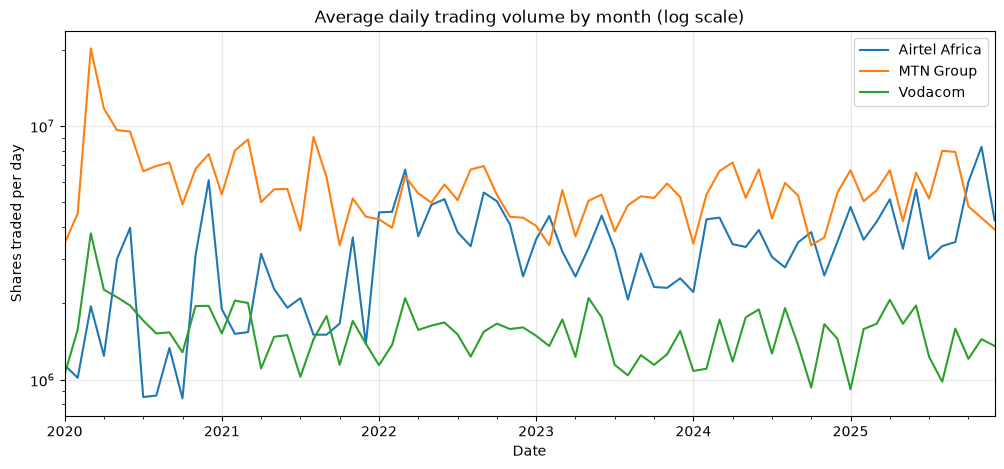

,Average daily volume,Median daily volume,Highest daily volume
Airtel Africa,3278895.0,2392885.0,82461685.0
MTN Group,5878340.0,4783634.0,82254233.0
Vodacom,1547754.0,1296880.0,11729490.0


In [7]:
daily_volume = pd.DataFrame({
    company: data["Volume"]
    for company, data in stock_data.items()
})

monthly_volume = daily_volume.resample("ME").mean()
monthly_volume.plot(logy=True, title="Average daily trading volume by month (log scale)")
plt.ylabel("Shares traded per day")
plt.show()

volume_summary = pd.DataFrame({
    "Average daily volume": daily_volume.mean(),
    "Median daily volume": daily_volume.median(),
    "Highest daily volume": daily_volume.max()
}).round(0)

volume_summary

## 8. Airtel Malawi vs TNM: MSE quarterly snapshot

The figures below were already present in the original notebook. They are entered manually and are **not** downloaded from Yahoo Finance. Before publishing, verify them against the official MSE Q3 2026 report and add the report URL or citation here.

This is a single-quarter snapshot, not daily data. We therefore cannot calculate daily moving averages or train a daily prediction model for these two Malawi-listed shares from this table alone.

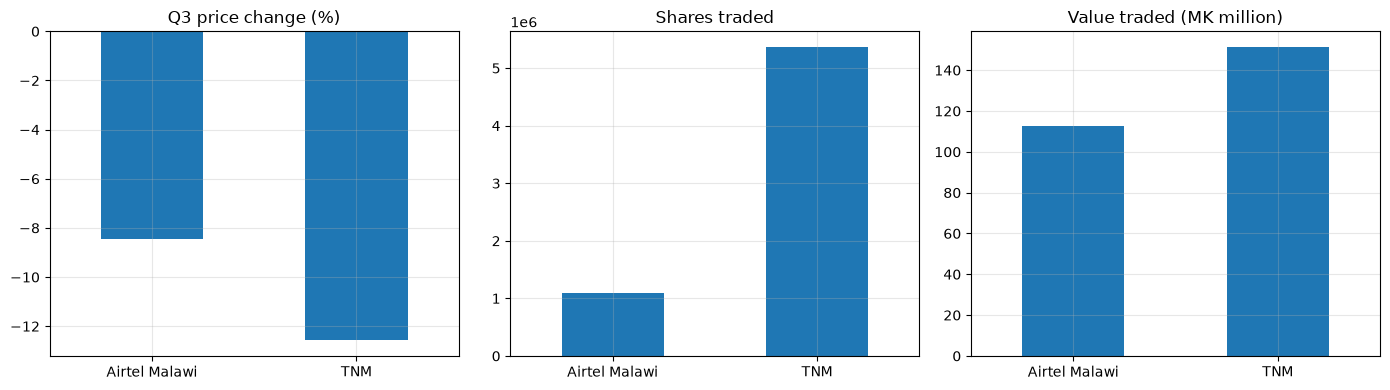

,Opening price (MK),Closing price (MK),Price change (%),Shares traded,Value traded (MK),Number of trades,Average traded price (MK)
Airtel Malawi,111.29,101.89,-8.45,1088106,1.126510e+08,409,103.53
TNM,29.17,25.50,-12.58,5370585,1.514504e+08,327,28.20


In [8]:
mse_data = pd.DataFrame({
    "Opening price (MK)": [111.29, 29.17],
    "Closing price (MK)": [101.89, 25.50],
    "Price change (%)": [-8.45, -12.58],
    "Shares traded": [1_088_106, 5_370_585],
    "Value traded (MK)": [112_650_993.34, 151_450_361.66],
    "Number of trades": [409, 327]
}, index=["Airtel Malawi", "TNM"])

mse_data["Average traded price (MK)"] = (
    mse_data["Value traded (MK)"] / mse_data["Shares traded"]
).round(2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
mse_data["Price change (%)"].plot.bar(ax=axes[0], title="Q3 price change (%)", rot=0)
mse_data["Shares traded"].plot.bar(ax=axes[1], title="Shares traded", rot=0)
(mse_data["Value traded (MK)"] / 1_000_000).plot.bar(
    ax=axes[2], title="Value traded (MK million)", rot=0
)
plt.tight_layout()
plt.show()

mse_data

## 9. Daily returns and volatility

A daily return measures the percentage change from one close to the next. Returns are more comparable than raw prices across different currencies.

The rolling 20-day standard deviation gives a simple view of how daily returns' volatility changes over time.

Percentage of observed days with a positive return:
Airtel Africa    50.4
MTN Group        47.3
Vodacom          47.0
dtype: float64

Correlation between daily returns:
               Airtel Africa  MTN Group  Vodacom
Airtel Africa           1.00       0.31     0.01
MTN Group               0.31       1.00    -0.02
Vodacom                 0.01      -0.02     1.00


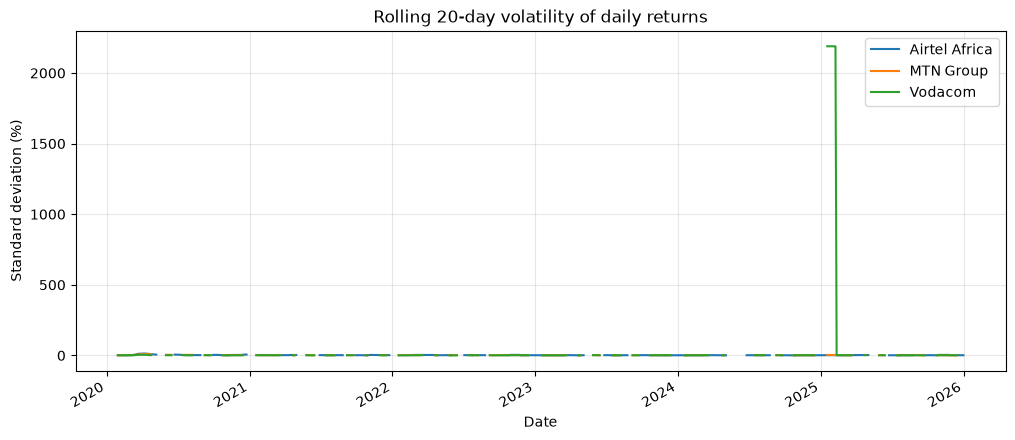

In [9]:
daily_returns = closing_prices.pct_change()

print("Percentage of observed days with a positive return:")
print((daily_returns > 0).mean().mul(100).round(1))

print("\nCorrelation between daily returns:")
print(daily_returns.corr().round(2))

(daily_returns.rolling(window=20).std() * 100).plot(
    title="Rolling 20-day volatility of daily returns"
)
plt.ylabel("Standard deviation (%)")
plt.show()

# Part 2: A simple prediction experiment

This section tests whether basic historical information can help predict if the next day's close will be higher.

**Important:** this is a learning experiment, not a trading system. Stock direction is difficult to predict. A model can perform well by chance, and results can change with different dates, costs and market conditions.

## 10. Create features and tomorrow's target

Each row describes information available at that day's close. The target is 1 when the next day's return is positive and 0 otherwise. We keep the next-day return only for evaluation and backtesting; it is not included in the feature list.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

feature_columns = [
    "return_1_day",
    "return_5_days",
    "return_20_days",
    "volatility_5_days",
    "volatility_20_days",
    "distance_from_20_day_average",
    "distance_from_200_day_average",
    "relative_volume",
    "high_low_range",
    "open_close_return"
]

def create_features(data):
    close = data["Close"]
    daily_return = close.pct_change()

    features = pd.DataFrame(index=data.index)

    features["return_1_day"] = daily_return
    features["return_5_days"] = close.pct_change(5)
    features["return_20_days"] = close.pct_change(20)

    features["volatility_5_days"] = daily_return.rolling(5).std()
    features["volatility_20_days"] = daily_return.rolling(20).std()

    features["distance_from_20_day_average"] = (
        close / close.rolling(20).mean() - 1
    )
    features["distance_from_200_day_average"] = (
        close / close.rolling(200).mean() - 1
    )

    features["relative_volume"] = (
        data["Volume"] / data["Volume"].rolling(20).mean()
    )
    features["high_low_range"] = (data["High"] - data["Low"]) / close
    features["open_close_return"] = close / data["Open"] - 1

    # Tomorrow's return is used to create the target and evaluate predictions
    features["next_day_return"] = daily_return.shift(-1)
    features["target"] = (features["next_day_return"] > 0).astype(int)

    # Remove rows where rolling calculations are not ready, or tomorrow is unknown
    features = features.replace([np.inf, -np.inf], np.nan)
    features = features.dropna()

    return features

feature_data = {}

for company, data in stock_data.items():
    feature_data[company] = create_features(data)
    print(
        company,
        "| usable rows:", len(feature_data[company]),
        "| share of up days:", round(feature_data[company]["target"].mean(), 3)
    )

Airtel Africa | usable rows: 1315 | share of up days: 0.527
MTN Group | usable rows: 1300 | share of up days: 0.502
Vodacom | usable rows: 1300 | share of up days: 0.497


## 11. Compare simple models using chronological splits

We do not shuffle stock data because that would let the model learn from the future and test on the past. Each test fold comes after its training fold.

We compare:
- **Baseline:** always predicts the most common direction in its training data.
- **Logistic regression:** a simple statistical classification model.
- **Random forest:** a collection of decision trees.

The one-row gap helps separate training labels from the first test row because each target uses the next day's return.

In [11]:
def make_models():
    models = {
        "baseline": DummyClassifier(strategy="most_frequent"),
        "logistic_regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=100,
            max_depth=4,
            min_samples_leaf=20,
            random_state=42
        )
    }
    return models


def evaluate_models(features, number_of_splits=5):
    X = features[feature_columns]
    y = features["target"]

    # Store out-of-sample probabilities for each model
    predictions = {
        model_name: pd.Series(index=features.index, dtype=float)
        for model_name in make_models()
    }

    splitter = TimeSeriesSplit(n_splits=number_of_splits, gap=1)

    for train_rows, test_rows in splitter.split(X):
        X_train = X.iloc[train_rows]
        y_train = y.iloc[train_rows]
        X_test = X.iloc[test_rows]

        for model_name, model in make_models().items():
            model.fit(X_train, y_train)
            predictions[model_name].iloc[test_rows] = model.predict_proba(X_test)[:, 1]

    predictions = pd.DataFrame(predictions).dropna()

    # Match actual targets to the dates that have predictions
    actual = features.loc[predictions.index, "target"]

    score_rows = []
    for model_name in predictions.columns:
        probability = predictions[model_name]
        predicted_direction = (probability > 0.5).astype(int)

        accuracy = accuracy_score(actual, predicted_direction)

        # A constant baseline probability cannot provide a meaningful ROC-AUC
        if model_name == "baseline" or actual.nunique() < 2:
            auc = np.nan
        else:
            auc = roc_auc_score(actual, probability)

        score_rows.append({
            "model": model_name,
            "accuracy": accuracy,
            "roc_auc": auc,
            "test_up_day_share": actual.mean(),
            "test_days": len(actual)
        })

    return predictions, pd.DataFrame(score_rows).set_index("model"), actual


all_predictions = {}
all_scores = []

for company, features in feature_data.items():
    predictions, scores, actual = evaluate_models(features)
    all_predictions[company] = predictions
    scores["company"] = company
    all_scores.append(scores.reset_index())

model_results = pd.concat(all_scores, ignore_index=True)
model_results = model_results[[
    "company", "model", "accuracy", "roc_auc", "test_up_day_share", "test_days"
]]
model_results.round(3)

,company,model,accuracy,roc_auc,test_up_day_share,test_days
0,Airtel Africa,baseline,0.525,NaN,0.525,1095
1,Airtel Africa,logistic_regression,0.509,0.506,0.525,1095
2,Airtel Africa,random_forest,0.499,0.503,0.525,1095
3,MTN Group,baseline,0.473,NaN,0.499,1080
4,MTN Group,logistic_regression,0.500,0.514,0.499,1080
5,MTN Group,random_forest,0.524,0.516,0.499,1080
6,Vodacom,baseline,0.498,NaN,0.502,1080
7,Vodacom,logistic_regression,0.525,0.522,0.502,1080
8,Vodacom,random_forest,0.531,0.521,0.502,1080


## 12. A simple out-of-sample backtest

For this experiment, the strategy holds the share when the predicted probability of an up day is above 50%; otherwise it stays in cash. It is compared with buying and holding over the same test dates.

The transaction cost below is only a placeholder. Replace it with realistic brokerage, taxes and spread assumptions for each market before drawing conclusions. This simplified backtest also assumes trades can be executed at the prices represented by the data, which may not be realistic.

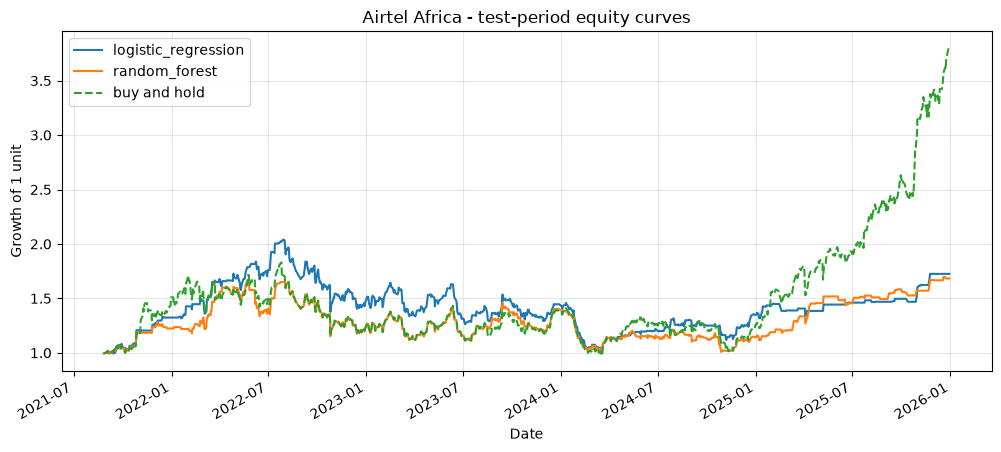

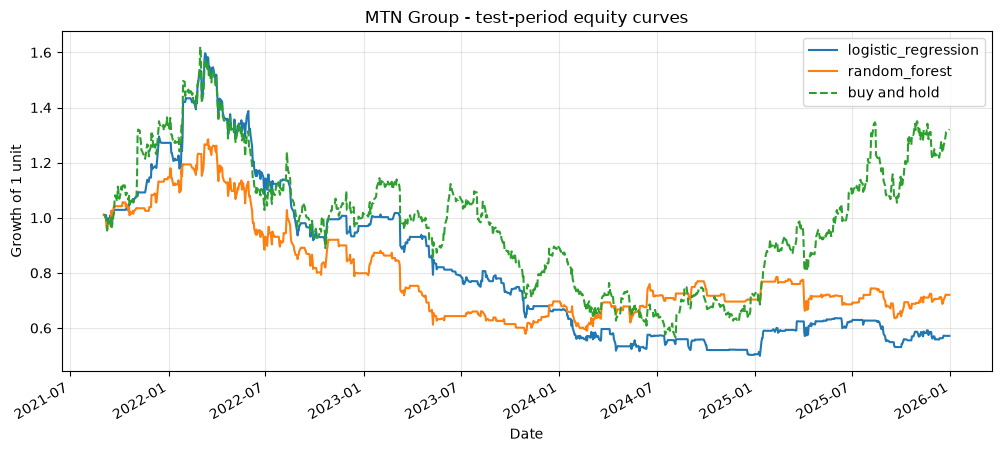

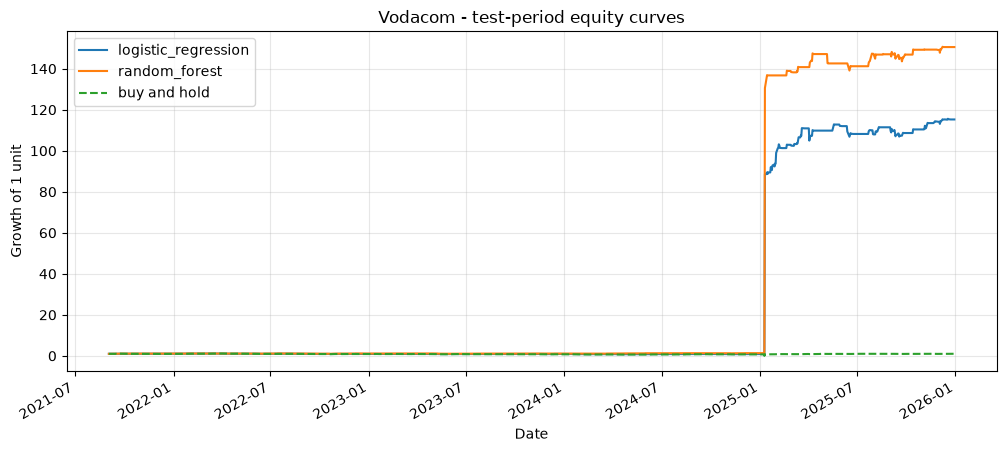

,company,strategy,total_return,maximum_drawdown,position_changes,share_of_days_in_market
0,Airtel Africa,buy_and_hold,2.809,-0.469,1,1.000
1,Airtel Africa,logistic_regression,0.725,-0.507,214,0.593
2,Airtel Africa,random_forest,0.683,-0.402,248,0.626
3,MTN Group,buy_and_hold,0.321,-0.650,1,1.000
4,MTN Group,logistic_regression,-0.428,-0.687,274,0.460
5,MTN Group,random_forest,-0.279,-0.549,314,0.453
6,Vodacom,buy_and_hold,0.016,-0.994,1,1.000
7,Vodacom,logistic_regression,114.262,-0.299,254,0.419
8,Vodacom,random_forest,149.558,-0.147,290,0.372


In [12]:
transaction_cost = 0.001  # placeholder: 0.1% each time the position changes

def backtest_strategy(next_day_returns, predicted_probabilities, cost):
    # Hold the share if predicted probability is above 50%, otherwise stay in cash
    position = (predicted_probabilities > 0.5).astype(int)

    # A trade happens when the position changes from cash to share or share to cash
    trades = position.diff().abs()
    trades.iloc[0] = position.iloc[0]

    strategy_returns = position * next_day_returns - trades * cost
    equity = (1 + strategy_returns).cumprod()

    drawdown = equity / equity.cummax() - 1

    summary = {
        "total_return": equity.iloc[-1] - 1,
        "maximum_drawdown": drawdown.min(),
        "position_changes": int(trades.sum()),
        "share_of_days_in_market": position.mean()
    }

    return equity, summary


backtest_rows = []

for company, features in feature_data.items():
    predictions = all_predictions[company]
    test_features = features.loc[predictions.index]
    next_returns = test_features["next_day_return"]

    # Buy-and-hold benchmark over exactly the same test dates
    buy_hold_equity = (1 + next_returns).cumprod()
    buy_hold_drawdown = buy_hold_equity / buy_hold_equity.cummax() - 1

    backtest_rows.append({
        "company": company,
        "strategy": "buy_and_hold",
        "total_return": buy_hold_equity.iloc[-1] - 1,
        "maximum_drawdown": buy_hold_drawdown.min(),
        "position_changes": 1,
        "share_of_days_in_market": 1.0
    })

    for model_name in ["logistic_regression", "random_forest"]:
        equity, summary = backtest_strategy(
            next_returns,
            predictions[model_name],
            transaction_cost
        )

        backtest_rows.append({
            "company": company,
            "strategy": model_name,
            **summary
        })

        equity.plot(label=model_name)

    buy_hold_equity.plot(label="buy and hold", linestyle="--")
    plt.title(company + " - test-period equity curves")
    plt.ylabel("Growth of 1 unit")
    plt.legend()
    plt.show()

backtest_results = pd.DataFrame(backtest_rows)
backtest_results.round(3)

## 13. Write your findings

After running all cells, answer these questions using the actual output:

1. Which share had the strongest rebased price performance over the period?
2. Which shares ended above or below their 200-day moving average?
3. Which model, if any, beat the baseline accuracy?
4. Are the ROC-AUC scores meaningfully above 0.50, or close to random ranking?
5. Did either model beat buy-and-hold after the assumed costs? What happened to maximum drawdown?
6. What are the biggest limitations?

### Limitations to mention

- Yahoo Finance data can be revised, missing, or unavailable.
- The three companies trade on different exchanges and in different currencies.
- Trading volume across exchanges is not directly comparable.
- The Malawi figures are manually entered and need an official source citation.
- A five-fold walk-forward test is useful, but it does not guarantee future performance.
- The cost assumption is only a placeholder.
- This project is an analysis exercise, not financial advice or evidence that a strategy will make money.

### Suggested next improvement

Before adding more complex models, make the data download repeatable, verify the MSE figures against the official report, save the charts, and write conclusions based on the results rather than guessing them in advance.